## Project Portofolio Data Analytics
#### Sentiment Analysis of Healthcare Applications: User Satisfaction and Service Improvement

#### Business problem: Perusahaan belum memiliki gambaran terstruktur mengenai sentimen pengguna dan aspek layanan yang paling sering dikeluhkan.

### Pertanyaan bisnis (5W + 1H)
Aspek	Pertanyaan analisis

What	Berapa proporsi ulasan positif, negatif, dan netral?

Who	    Bagaimana pengalaman pengguna tercermin dalam ulasan?

Where	Aplikasi atau platform mana yang memiliki sentimen lebih baik, jika data mendukung perbandingan?

When	Bagaimana sentimen berubah dari waktu ke waktu?

Why	    Apa keluhan atau apresiasi yang paling sering muncul?

How	    Perbaikan layanan apa yang dapat diprioritaskan berdasarkan hasil analisis?

Target akhirnya: menghasilkan dashboard yang membantu tim produk memprioritaskan perbaikan, misalnya proses pendaftaran, konsultasi dokter, pemesanan janji, atau stabilitas aplikasi.

Catatan: aspek layanan tersebut merupakan contoh kategori yang akan kita teliti, bukan kesimpulan sebelum data dianalisis.

Dataset : https://data.mendeley.com/datasets/rmmmf2dp8d/2

Indonesian Telemedicine User Review Dataset
Dataset sekitar 19.680 ulasan dari tiga aplikasi telemedicine Indonesia, dengan informasi platform, nama aplikasi, rating, teks ulasan, sentimen, dan bobot kompleksitas ulasan. Tersedia label positif, netral, dan negatif.

#### Libraries

In [19]:
import pandas as pd
import re
import matplotlib.pyplot as plt


In [2]:
path_file = r"C:\Users\Siti Sartika H\Downloads\WeightedSentimentTelemedicineDataset.csv"

df_sentimen = pd.read_csv(path_file)
df_sentimen.head(5)

,platform,app_name,rating,review,sentiment,weight
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE


In [3]:
df_sentimen.info()

<class 'pandas.DataFrame'>
RangeIndex: 19680 entries, 0 to 19679
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   platform   19680 non-null  str  
 1   app_name   19680 non-null  str  
 2   rating     19680 non-null  int64
 3   review     19628 non-null  str  
 4   sentiment  19680 non-null  str  
 5   weight     19680 non-null  str  
dtypes: int64(1), str(5)
memory usage: 922.6 KB


In [5]:
# 1. Standarisasi nama kolom
df_sentimen.columns = (
    df_sentimen.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
)

In [6]:
df_sentimen

,platform,app_name,rating,review,sentiment,weight
0,Play Store,Alodokter —Chat Bersama Dokter,5,oke,NEUTRAL,UNINFORMATIVE
1,Play Store,Alodokter —Chat Bersama Dokter,2,"baru download, mau daftar ga bisa2. haduuhhh t...",NEGATIVE,UNINFORMATIVE
2,Play Store,Alodokter —Chat Bersama Dokter,1,mending chat sama chatgpt dari pada alodokter....,NEGATIVE,UNINFORMATIVE
3,Play Store,Alodokter —Chat Bersama Dokter,5,Sangat Memuaskan,POSITIVE,UNINFORMATIVE
4,Play Store,Alodokter —Chat Bersama Dokter,5,"saya usia 54 thn sering sakit gigi, klau sakit...",NEUTRAL,UNINFORMATIVE
...,...,...,...,...,...,...
19675,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah mngetahui tntng kshatan gaya hdup ...,POSITIVE,UNINFORMATIVE
19676,Play Store,KlikDokter: Jaga Sehatmu,5,Semua ulasan,POSITIVE,UNINFORMATIVE
19677,Play Store,KlikDokter: Jaga Sehatmu,4,BAguz,POSITIVE,UNINFORMATIVE
19678,Play Store,KlikDokter: Jaga Sehatmu,5,Mempermudah kita jika mau berkonsultasi dengan...,POSITIVE,UNINFORMATIVE


In [ ]:
# 2. Pastikan kolom penting tersedia
required_columns = [
    "app_name", "rating", "review", "sentiment"
]

missing = set(required_columns) - set(df_sentimen.columns)

if missing:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {missing}"
    )

In [9]:
# Jumlah missing value
missing_review = df_sentimen['review'].isnull().sum()

# Total baris data
total_data = len(df_sentimen)

# Persentase missing value
persentase_missing = (missing_review / total_data) * 100

print("Total data:", total_data)
print("Missing value pada review:", missing_review)
print(f"Persentase missing value: {persentase_missing:.2f}%")

Total data: 19680
Missing value pada review: 52
Persentase missing value: 0.26%


In [10]:
# 3. Hapus ulasan kosong
df_sentimen = df_sentimen.dropna(subset=["review", "sentiment"]).copy()

df_sentimen["review"] = df_sentimen["review"].astype(str).str.strip()
df_sentimen = df_sentimen[df_sentimen["review"] != ""]

In [12]:
# 4. Hapus ulasan duplikat
df_sentimen = df_sentimen.drop_duplicates(
    subset=["app_name", "review"]
).copy()

In [13]:
# 5. Bersihkan teks, pertahankan kata dan angka
def clean_review(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df_sentimen["review_clean"] = df_sentimen["review"].apply(clean_review)

In [14]:
# 6. Normalisasi label sentimen
df_sentimen["sentiment"] = (
    df_sentimen["sentiment"]
    .astype(str)
    .str.strip()
    .str.lower()
)

label_mapping = {
    "positive": "Positif",
    "positif": "Positif",
    "neutral": "Netral",
    "netral": "Netral",
    "negative": "Negatif",
    "negatif": "Negatif"
}

df_sentimen["sentiment"] = df_sentimen["sentiment"].map(label_mapping)

In [15]:
# 7. Validasi rating
df_sentimen["rating"] = pd.to_numeric(
    df_sentimen["rating"], errors="coerce"
)

df_sentimen.loc[
    ~df_sentimen["rating"].between(1, 5),
    "rating"
] = float("nan")

# 8. Hanya simpan label yang dikenal
df_sentimen = df_sentimen.dropna(subset=["sentiment"]).copy()

# 9. Buat ID unik untuk setiap baris hasil
df_sentimen = df_sentimen.reset_index(drop=True)
df_sentimen.insert(0, "review_id", range(1, len(df_sentimen) + 1))

print("Jumlah data setelah cleaning:", len(df_sentimen))
print("\nDistribusi sentimen:")
print(df_sentimen["sentiment"].value_counts())

print("\nData setelah transformasi:")
print(df_sentimen.head())

Jumlah data setelah cleaning: 19460

Distribusi sentimen:
sentiment
Positif    14535
Negatif     4216
Netral       709
Name: count, dtype: int64

Data setelah transformasi:
   review_id    platform                        app_name  rating  \
0          1  Play Store  Alodokter —Chat Bersama Dokter     5.0   
1          2  Play Store  Alodokter —Chat Bersama Dokter     2.0   
2          3  Play Store  Alodokter —Chat Bersama Dokter     1.0   
3          4  Play Store  Alodokter —Chat Bersama Dokter     5.0   
4          5  Play Store  Alodokter —Chat Bersama Dokter     5.0   

                                              review sentiment         weight  \
0                                                oke    Netral  UNINFORMATIVE   
1  baru download, mau daftar ga bisa2. haduuhhh t...   Negatif  UNINFORMATIVE   
2  mending chat sama chatgpt dari pada alodokter....   Negatif  UNINFORMATIVE   
3                                   Sangat Memuaskan   Positif  UNINFORMATIVE   
4  saya usia 

In [16]:
# Statistik deskriptif
print("\nStatistik deskriptif:")
print(df_sentimen.describe(include="all"))

# Missing value setiap kolom
print("\nJumlah missing value:")
print(df_sentimen.isnull().sum())

# Persentase missing value
print("\nPersentase missing value (%):")
print((df_sentimen.isnull().sum() / len(df_sentimen) * 100).round(2))

# Jumlah data duplikat
print("\nJumlah data duplikat:", df_sentimen.duplicated().sum())



Statistik deskriptif:
           review_id    platform                        app_name  \
count   19460.000000       19460                           19460   
unique           NaN           1                               3   
top              NaN  Play Store  Alodokter —Chat Bersama Dokter   
freq             NaN       19460                            7514   
mean     9730.500000         NaN                             NaN   
std      5617.762455         NaN                             NaN   
min         1.000000         NaN                             NaN   
25%      4865.750000         NaN                             NaN   
50%      9730.500000         NaN                             NaN   
75%     14595.250000         NaN                             NaN   
max     19460.000000         NaN                             NaN   

              rating review sentiment         weight     review_clean  
count   19460.000000  19460     19460          19460            19460  
unique          

In [17]:
# Daftar aplikasi unik, tanpa missing value
app_list = sorted(df_sentimen["app_name"].dropna().unique())

for app in app_list:
    print(app)

Alodokter —Chat Bersama Dokter
Halodoc: Dokter, Obat & Lab
KlikDokter: Jaga Sehatmu


In [18]:
# Simpan data yang sudah dibersihkan ke CSV
df_sentimen.to_csv(
    "sentimen_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Data berhasil disimpan!")

Data berhasil disimpan!


           Jumlah  Persentase (%)
sentiment                        
Positif     14535           74.69
Negatif      4216           21.66
Netral        709            3.64


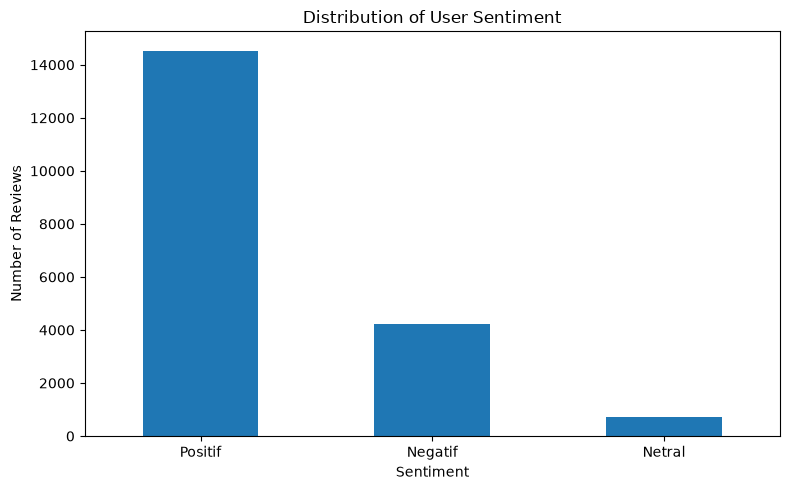

In [20]:
# Menghitung jumlah tiap sentimen
sentiment_count = df_sentimen["sentiment"].value_counts()

# Menghitung persentase tiap sentimen
sentiment_percentage = (
    df_sentimen["sentiment"].value_counts(normalize=True) * 100
).round(2)

# Menggabungkan hasil
sentiment_summary = pd.DataFrame({
    "Jumlah": sentiment_count,
    "Persentase (%)": sentiment_percentage
})

print(sentiment_summary)

# Visualisasi distribusi sentimen
sentiment_count.plot(kind="bar", figsize=(8, 5))

plt.title("Distribution of User Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Jumlah sentimen per aplikasi:
sentiment                       Negatif  Netral  Positif
app_name                                                
Alodokter —Chat Bersama Dokter     2256     426     4832
Halodoc: Dokter, Obat & Lab        1029      66     6117
KlikDokter: Jaga Sehatmu            931     217     3586

Persentase sentimen per aplikasi (%):
sentiment                       Negatif  Netral  Positif
app_name                                                
Alodokter —Chat Bersama Dokter    30.02    5.67    64.31
Halodoc: Dokter, Obat & Lab       14.27    0.92    84.82
KlikDokter: Jaga Sehatmu          19.67    4.58    75.75


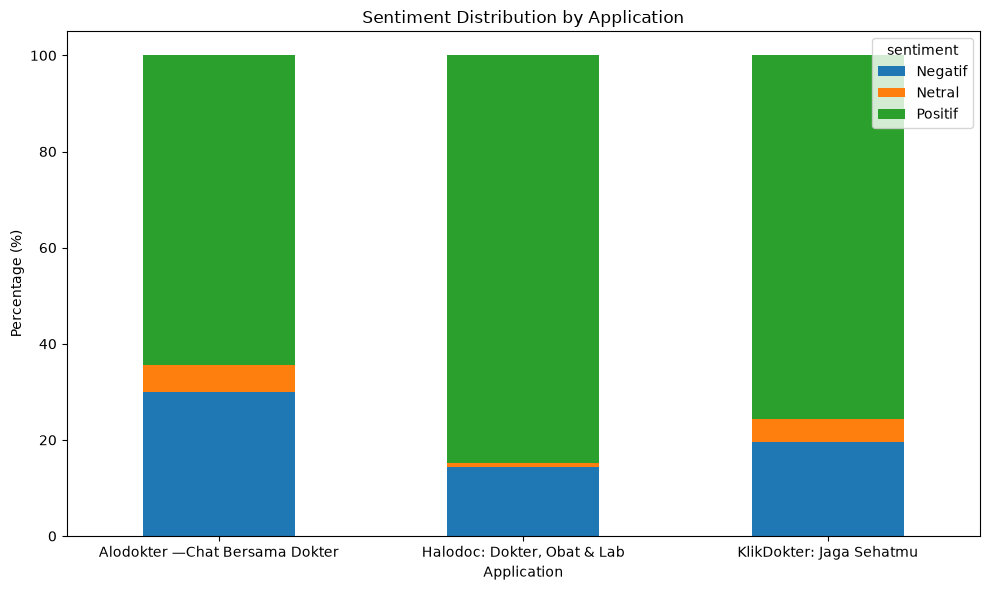

In [25]:
# Menghitung jumlah ulasan per aplikasi dan sentimen
app_sentiment_count = pd.crosstab(
    df_sentimen["app_name"],
    df_sentimen["sentiment"]
)

print("Jumlah sentimen per aplikasi:")
print(app_sentiment_count)

# Menghitung persentase sentimen di dalam setiap aplikasi
app_sentiment_percentage = (
    pd.crosstab(
        df_sentimen["app_name"],
        df_sentimen["sentiment"],
        normalize="index"
    ) * 100
).round(2)

print("\nPersentase sentimen per aplikasi (%):")
print(app_sentiment_percentage)

# Visualisasi persentase
app_sentiment_percentage.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sentiment Distribution by Application")
plt.xlabel("Application")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0, ha="center")
plt.tight_layout()
plt.show()

In [26]:
# Memeriksa jumlah ulasan per sentimen
print(df_sentimen.groupby("sentiment")["review_clean"].count())

# Mengambil ulasan positif
positive_reviews = df_sentimen.loc[
    df_sentimen["sentiment"].astype(str).str.lower().isin(
        ["positive", "positif"]
    ),
    "review_clean"
].dropna()

# Mengambil ulasan negatif
negative_reviews = df_sentimen.loc[
    df_sentimen["sentiment"].astype(str).str.lower().isin(
        ["negative", "negatif"]
    ),
    "review_clean"
].dropna()

print("\nContoh ulasan positif:")
print(positive_reviews.head(5).to_string(index=False))

print("\nContoh ulasan negatif:")
print(negative_reviews.head(5).to_string(index=False))


sentiment
Negatif     4216
Netral       709
Positif    14535
Name: review_clean, dtype: int64

Contoh ulasan positif:
                               sangat memuaskan
                  bisa bertanya tentang kesehat
petunjuk dokter dan konsultasi menenangkan hati
                                     informatif
                       mantabbb tp jangan bayar

Contoh ulasan negatif:
baru download mau daftar ga bisa2 haduuhhh teru...
mending chat sama chatgpt dari pada alodokter g...
dokternya responnya lama semoga bisa diperbaiki...
aplikasi ini engga amanah saya order yang insta...
syaa sudah konsul dokter sp m di kasih resep ob...


In [27]:
print("Ukuran dataset:", df_sentimen.shape)

print("\nMissing value per kolom:")
print(df_sentimen.isnull().sum())

print("\nLabel sentiment yang tersedia:")
print(df_sentimen["sentiment"].value_counts(dropna=False))

print("\nJumlah aplikasi:")
print(df_sentimen["app_name"].nunique())

print("\nDaftar aplikasi:")
print(df_sentimen["app_name"].dropna().unique())

print("\nJumlah platform:")
print(df_sentimen["platform"].nunique())

print("\nDaftar platform:")
print(df_sentimen["platform"].dropna().unique())


Ukuran dataset: (19460, 8)

Missing value per kolom:
review_id       0
platform        0
app_name        0
rating          0
review          0
sentiment       0
weight          0
review_clean    0
dtype: int64

Label sentiment yang tersedia:
sentiment
Positif    14535
Negatif     4216
Netral       709
Name: count, dtype: int64

Jumlah aplikasi:
3

Daftar aplikasi:
<StringArray>
['Alodokter —Chat Bersama Dokter',    'Halodoc: Dokter, Obat & Lab',
       'KlikDokter: Jaga Sehatmu']
Length: 3, dtype: str

Jumlah platform:
1

Daftar platform:
<StringArray>
['Play Store']
Length: 1, dtype: str


In [28]:
import re
from collections import Counter

# Pastikan df sudah berisi dataset hasil transformasi
# Normalisasi label sentimen
df_sentimen["sentiment_norm"] = (
    df_sentimen["sentiment"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Periksa label sentimen yang tersedia
print("Label sentimen dalam dataset:")
print(df_sentimen["sentiment_norm"].value_counts(dropna=False))

# Pisahkan ulasan positif dan negatif
positive_reviews = df_sentimen.loc[
    df_sentimen["sentiment_norm"].isin(["positive", "positif"]),
    "review_clean"
].dropna()

negative_reviews = df_sentimen.loc[
    df_sentimen["sentiment_norm"].isin(["negative", "negatif"]),
    "review_clean"
].dropna()

# Stopwords sederhana
stopwords = set("""
dan yang di ke dari untuk dengan ini itu saya aku anda kamu
nya tidak ada pada dalam karena tapi sangat bisa sudah kalau
the a an and is are to of for in on it this that was with
""".split())

def get_top_words(text_series, top_n=15):
    words = []

    for text in text_series.astype(str):
        tokens = re.findall(r"\b[a-zA-Z]+\b", text.lower())
        words.extend(
            word for word in tokens
            if len(word) > 2 and word not in stopwords
        )

    return pd.DataFrame(
        Counter(words).most_common(top_n),
        columns=["Kata", "Frekuensi"]
    )

# Hitung kata paling sering muncul
top_positive_words = get_top_words(positive_reviews)
top_negative_words = get_top_words(negative_reviews)

print("\nKata yang sering muncul pada ulasan positif:")
print(top_positive_words.to_string(index=False))

print("\nKata yang sering muncul pada ulasan negatif:")
print(top_negative_words.to_string(index=False))


Label sentimen dalam dataset:
sentiment_norm
positif    14535
negatif     4216
netral       709
Name: count, dtype: Int64

Kata yang sering muncul pada ulasan positif:
       Kata  Frekuensi
     dokter       3728
   membantu       3644
  dokternya       1873
      cepat       1856
   aplikasi       1656
       baik       1569
      ramah       1520
      bagus       1497
     respon       1305
 konsultasi       1197
     sekali       1079
terimakasih        936
     banget        913
      kasih        835
      mudah        803

Kata yang sering muncul pada ulasan negatif:
      Kata  Frekuensi
    dokter       1475
  aplikasi       1079
     bayar       1032
      chat        973
      obat        827
       gak        699
       mau        657
      udah        608
konsultasi        592
     malah        528
      sama        510
      lagi        510
      lama        499
       aja        493
   padahal        474


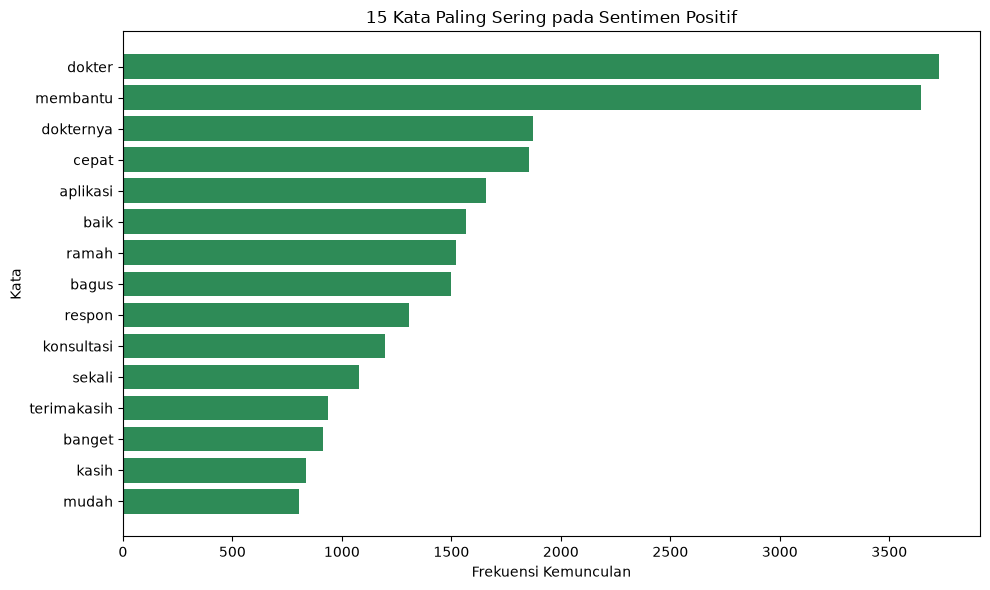

In [29]:
import re
from collections import Counter
import matplotlib.pyplot as plt

# Filter ulasan positif
positive_reviews = df_sentimen.loc[
    df_sentimen["sentiment_norm"].str.lower().str.strip() == "positif",
    "review_clean"
].dropna()

# Gabungkan seluruh ulasan
positive_text = " ".join(positive_reviews.astype(str))

# Ambil kata-kata
positive_words = re.findall(r"\b[a-zA-Z]+\b", positive_text.lower())

# Hapus stopwords sederhana
stopwords = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu",
    "saya", "aku", "nya", "untuk", "dengan", "ada",
    "sangat", "yg", "ga", "gak", "tidak", "ya", "aja",
    "juga", "karena", "sudah", "udah", "lebih", "bisa"
}

filtered_positive = [
    word for word in positive_words
    if word not in stopwords
]

# Ambil 15 kata teratas
top_positive = Counter(filtered_positive).most_common(15)

positive_df = pd.DataFrame(
    top_positive,
    columns=["kata", "frekuensi"]
)

# Visualisasi
plt.figure(figsize=(10, 6))
plt.barh(
    positive_df["kata"][::-1],
    positive_df["frekuensi"][::-1],
    color="seagreen"
)

plt.title("15 Kata Paling Sering pada Sentimen Positif")
plt.xlabel("Frekuensi Kemunculan")
plt.ylabel("Kata")
plt.tight_layout()

plt.show()

In [30]:

# Ambil contoh ulasan negatif berdasarkan kata kunci
keywords = ["bayar", "chat", "lama", "obat"]

for keyword in keywords:
    mask = (
        df_sentimen["sentiment_norm"].eq("negatif")
        & df_sentimen["review_clean"].astype("string").str.contains(
            rf"\b{keyword}\b",
            case=False,
            na=False,
            regex=True
        )
    )

    examples = df_sentimen.loc[mask, "review_clean"].dropna().drop_duplicates().head(5)

    print(f"\n=== Kata kunci: {keyword} ===")
    print("Jumlah baris yang mengandung kata:", int(mask.sum()))

    for i, review in enumerate(examples, start=1):
        print(f"{i}. {review}")



=== Kata kunci: bayar ===
Jumlah baris yang mengandung kata: 871
1. seperti saya orang susah mau chat gk ada uang pake bayar
2. sudah bayar untuk konsultasi dokter malah ngk bisa di buka ini aplikasi
3. gak ada yg geratis konsultasinya bayar
4. pas mau bayar pakai ovo sukses tiba tiba dokter sibuk gak ada pilihan lain pas pencet back eh kirain ada saldo gitu di akun pas mau order lagi suruh topup lagi hangus dah uangku
5. sudah bayar tapi gabisa memulai chat udah berpuluh menit komplain ke whatsapp tidak ada respon

=== Kata kunci: chat ===
Jumlah baris yang mengandung kata: 755
1. mending chat sama chatgpt dari pada alodokter ga bisa keluarin surat dokter gara2 abis katanya jawaban nya jg textbook banget mending chat ai aja gratis
2. seperti saya orang susah mau chat gk ada uang pake bayar
3. setiap chat dokter selalu je scroll otomatis kebawah jadi antara pasien dgn dokter kesulitan baca chat keluhannya yg panjang gmna nih masa chat pendek pendek utk ngasih tau keluhannya segera per

In [31]:
# Ambil ulasan negatif
negative_df = df_sentimen[
    df_sentimen["sentiment_norm"].eq("negatif")
].copy()

# Tema dan kata kunci untuk identifikasi awal
themes = {
    "Pembayaran dan refund":
        r"\bbayar\b|\bpembayaran\b|\brefund\b|\bdana\b|\bsaldo\b|\btopup\b",

    "Konsultasi dan chat":
        r"\bchat\b|\bkonsultasi\b|\bkonsul\b|\bkonsultasi\b",

    "Respons dan waktu tunggu":
        r"\blama\b|\bmenunggu\b|\bnunggu\b|\brespon\b|\brespons\b",

    "Pembelian dan pengiriman obat":
        r"\bobat\b|\bpengiriman\b|\bdikirim\b|\bpesanan\b|\bapotik\b"
}

results = []

for theme, pattern in themes.items():
    mask = negative_df["review_clean"].astype("string").str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    )

    results.append({
        "Tema": theme,
        "Jumlah ulasan": int(mask.sum()),
        "Persentase dari ulasan negatif (%)": round(
            mask.mean() * 100, 2
        ) if len(mask) else 0
    })

theme_summary = pd.DataFrame(results).sort_values(
    "Jumlah ulasan", ascending=False
)

print(theme_summary.to_string(index=False))


                         Tema  Jumlah ulasan  Persentase dari ulasan negatif (%)
          Konsultasi dan chat           1356                               32.16
        Pembayaran dan refund           1188                               28.18
     Respons dan waktu tunggu            803                               19.05
Pembelian dan pengiriman obat            654                               15.51


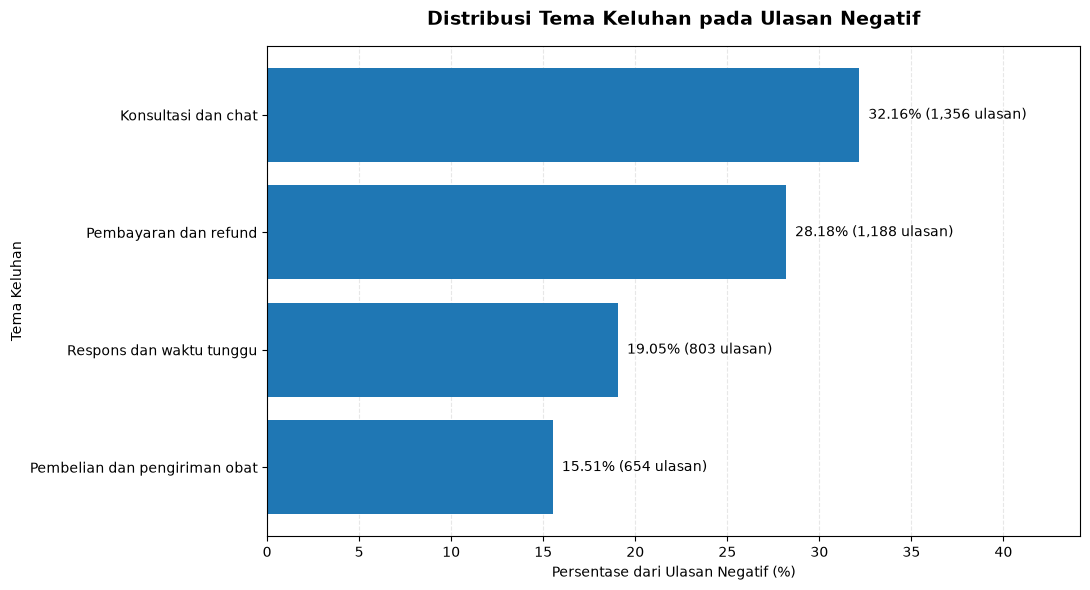

In [32]:
# Data hasil analisis sentimen negatif
data = {
    "Tema": [
        "Konsultasi dan chat",
        "Pembayaran dan refund",
        "Respons dan waktu tunggu",
        "Pembelian dan pengiriman obat"
    ],
    "Jumlah ulasan": [1356, 1188, 803, 654],
    "Persentase (%)": [32.16, 28.18, 19.05, 15.51]
}

df_tema = pd.DataFrame(data)

# Urutkan dari persentase tertinggi ke terendah
df_tema = df_tema.sort_values(
    "Persentase (%)", ascending=True
)

# Membuat grafik
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    df_tema["Tema"],
    df_tema["Persentase (%)"]
)

# Menampilkan jumlah dan persentase di ujung batang
for bar, jumlah, persen in zip(
    bars,
    df_tema["Jumlah ulasan"],
    df_tema["Persentase (%)"]
):
    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{persen:.2f}% ({jumlah:,} ulasan)",
        va="center",
        fontsize=10
    )

ax.set_title(
    "Distribusi Tema Keluhan pada Ulasan Negatif",
    fontsize=14,
    fontweight="bold",
    pad=15
)
ax.set_xlabel("Persentase dari Ulasan Negatif (%)")
ax.set_ylabel("Tema Keluhan")

ax.set_xlim(0, max(df_tema["Persentase (%)"]) + 12)
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Simpan grafik untuk laporan atau presentasi
plt.savefig(
    "grafik_tema_keluhan_negatif.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
import pandas as pd

def classify_theme(review):
    review = str(review).lower()

    if any(word in review for word in [
        "refund", "pengembalian dana",
        "pembayaran", "bayar", "tagihan"
    ]):
        return "Pembayaran dan refund"

    elif any(word in review for word in [
        "dokter", "konsultasi", "chat",
        "balas", "respon"
    ]):
        return "Konsultasi dan chat"

    elif any(word in review for word in [
        "lama", "menunggu", "nunggu",
        "antri", "respons", "respon"
    ]):
        return "Respons dan waktu tunggu"

    elif any(word in review for word in [
        "obat", "pengiriman", "pesanan",
        "kurir", "dikirim"
    ]):
        return "Pembelian dan pengiriman obat"

    else:
        return "Lainnya"

In [34]:
df_negative = df_sentimen[
    df_sentimen["sentiment_norm"] == "negatif"
].copy()

df_negative["tema_sentimen"] = (
    df_negative["review_clean"]
    .apply(classify_theme)
)

In [35]:
df_tema = (
    df_negative
    .groupby(
        ["app_name", "tema_sentimen"],
        as_index=False
    )
    .agg(
        jumlah_ulasan=("review_id", "nunique")
    )
)

df_tema.to_csv(
    "tema_sentimen_per_aplikasi.csv",
    index=False,
    encoding="utf-8-sig"
)

print(df_tema.head())

                         app_name                  tema_sentimen  \
0  Alodokter —Chat Bersama Dokter            Konsultasi dan chat   
1  Alodokter —Chat Bersama Dokter                        Lainnya   
2  Alodokter —Chat Bersama Dokter          Pembayaran dan refund   
3  Alodokter —Chat Bersama Dokter  Pembelian dan pengiriman obat   
4  Alodokter —Chat Bersama Dokter       Respons dan waktu tunggu   

   jumlah_ulasan  
0            605  
1            657  
2            839  
3             75  
4             80  


1. Hubungan rating dan sentimen

Tujuan analisis

Mengetahui apakah terdapat hubungan antara rating yang diberikan pengguna dan label sentimen ulasan, yaitu positif, negatif, dan netral.
Contohnya, apakah ulasan dengan rating rendah cenderung memiliki sentimen negatif, sedangkan rating tinggi cenderung memiliki sentimen positif?
Variabel yang digunakan
Variabel	Jenis data	Contoh
rating	Kategorikal ordinal jika berupa skor bintang	1, 2, 3, 4, 5
sentiment_norm	Kategorikal nominal	Positif, negatif, netral

Metode: Chi-square test of independence
Uji Chi-square digunakan untuk mengetahui apakah dua variabel kategorikal saling berhubungan secara statistik.

Hipotesis yang diuji:
- H₀ (hipotesis nol): Tidak terdapat hubungan antara rating dan sentimen.
- H₁ (hipotesis alternatif): Terdapat hubungan antara rating dan sentimen.

Tingkat signifikansi yang digunakan adalah 5% atau \(\alpha=0{,}05\).

In [36]:
import pandas as pd
from scipy.stats import chi2_contingency
import numpy as np

# Siapkan data
data_uji = df_sentimen[["rating", "sentiment_norm"]].copy()

data_uji["rating"] = pd.to_numeric(
    data_uji["rating"], errors="coerce"
)

data_uji = data_uji.dropna(
    subset=["rating", "sentiment_norm"]
)

# Tabel silang rating dan sentimen
tabel = pd.crosstab(
    data_uji["rating"],
    data_uji["sentiment_norm"]
)

print("Tabel silang rating dan sentimen:")
print(tabel)

# Uji Chi-square
chi2, p_value, dof, expected = chi2_contingency(tabel)

# Cramer's V untuk mengukur kekuatan hubungan
n = tabel.to_numpy().sum()
r, k = tabel.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print("\nHasil Chi-square")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")
print(
    "Proporsi expected count < 5:",
    f"{(expected < 5).mean():.2%}"
)

if p_value < 0.05:
    print("Kesimpulan: terdapat hubungan yang signifikan.")
else:
    print("Kesimpulan: belum ada bukti hubungan yang signifikan.")


Tabel silang rating dan sentimen:
sentiment_norm  negatif  netral  positif
rating                                  
1.0                3195      20        3
2.0                 457      79       63
3.0                 414     187       79
4.0                  79      96      980
5.0                  71     327    13410

Hasil Chi-square
Chi-square statistic: 18684.4399
Degrees of freedom: 8
P-value: 0
Cramer's V: 0.6929
Proporsi expected count < 5: 0.00%
Kesimpulan: terdapat hubungan yang signifikan.


In [37]:
from scipy.stats import chi2_contingency

# Siapkan data
data_app = df_sentimen[["app_name", "sentiment_norm"]].copy()

data_app = data_app.dropna(
    subset=["app_name", "sentiment_norm"]
)

# Tabel silang aplikasi dan sentimen
tabel_app = pd.crosstab(
    data_app["app_name"],
    data_app["sentiment_norm"]
)

print("Jumlah ulasan berdasarkan aplikasi dan sentimen:")
print(tabel_app)

# Persentase sentimen di setiap aplikasi
persentase_app = (
    pd.crosstab(
        data_app["app_name"],
        data_app["sentiment_norm"],
        normalize="index"
    ) * 100
)

print("\nPersentase sentimen per aplikasi:")
print(persentase_app.round(2))

# Uji Chi-square
chi2, p_value, dof, expected = chi2_contingency(tabel_app)

n = tabel_app.to_numpy().sum()
r, k = tabel_app.shape

cramers_v = np.sqrt(
    chi2 / (n * min(r - 1, k - 1))
)

print("\nHasil pengujian")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"P-value: {p_value:.6g}")
print(f"Cramer's V: {cramers_v:.4f}")
print(
    "Proporsi expected count < 5:",
    f"{(expected < 5).mean():.2%}"
)

if p_value < 0.05:
    print("Kesimpulan: distribusi sentimen berbeda secara signifikan.")
else:
    print("Kesimpulan: belum ada bukti perbedaan yang signifikan.")


Jumlah ulasan berdasarkan aplikasi dan sentimen:
sentiment_norm                  negatif  netral  positif
app_name                                                
Alodokter —Chat Bersama Dokter     2256     426     4832
Halodoc: Dokter, Obat & Lab        1029      66     6117
KlikDokter: Jaga Sehatmu            931     217     3586

Persentase sentimen per aplikasi:
sentiment_norm                  negatif  netral  positif
app_name                                                
Alodokter —Chat Bersama Dokter    30.02    5.67    64.31
Halodoc: Dokter, Obat & Lab       14.27    0.92    84.82
KlikDokter: Jaga Sehatmu          19.67    4.58    75.75

Hasil pengujian
Chi-square statistic: 884.8990
Degrees of freedom: 4
P-value: 3.11511e-190
Cramer's V: 0.1508
Proporsi expected count < 5: 0.00%
Kesimpulan: distribusi sentimen berbeda secara signifikan.


Jumlah ulasan per aplikasi:
sentiment_norm                  positif  negatif  netral  Total Ulasan
app_name                                                              
Alodokter —Chat Bersama Dokter     4832     2256     426          7514
Halodoc: Dokter, Obat & Lab        6117     1029      66          7212
KlikDokter: Jaga Sehatmu           3586      931     217          4734


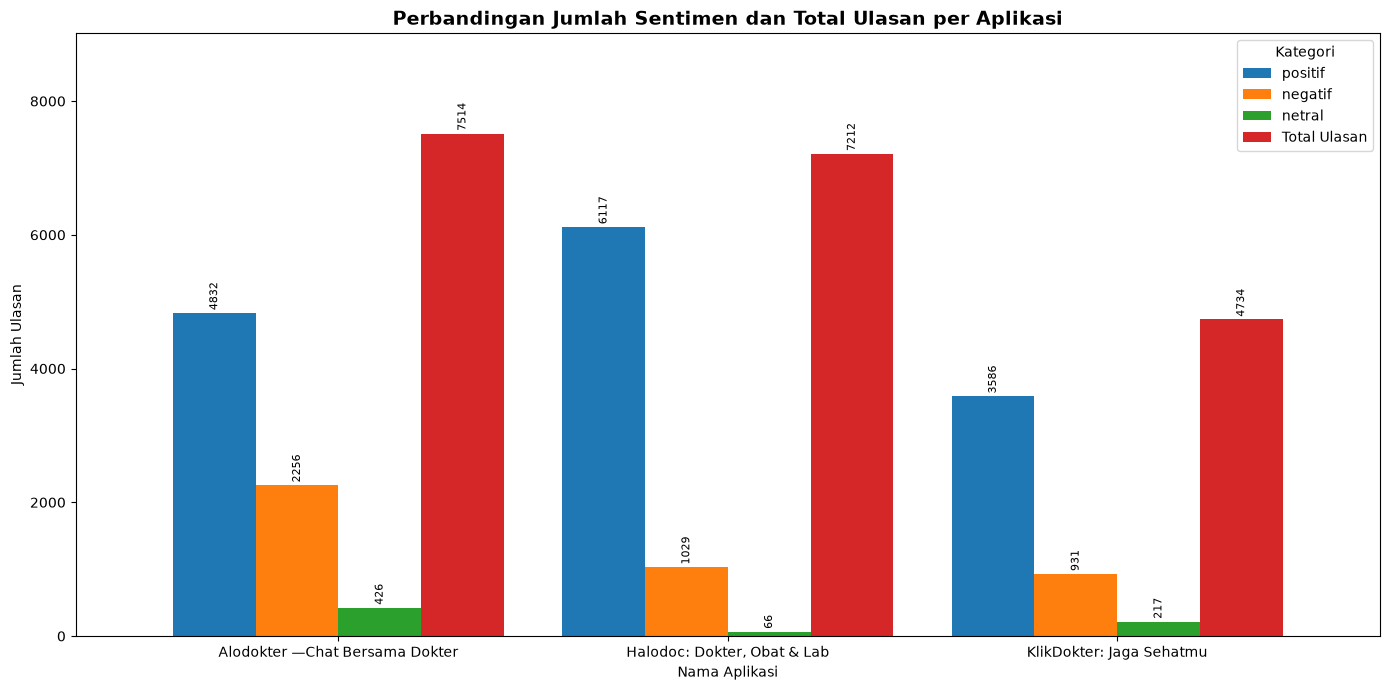

In [66]:
# 1. Membuat tabel jumlah sentimen setiap aplikasi
tabel_aplikasi = pd.crosstab(
    df_sentimen["app_name"],
    df_sentimen["sentiment_norm"]
)

# Memastikan semua kategori sentimen tersedia
tabel_aplikasi = tabel_aplikasi.reindex(
    columns=["positif", "negatif", "netral"],
    fill_value=0
)

# 2. Menghitung total ulasan setiap aplikasi
tabel_aplikasi["Total Ulasan"] = tabel_aplikasi[
    ["positif", "negatif", "netral"]
].sum(axis=1)

# Urutkan berdasarkan total ulasan terbanyak
tabel_aplikasi = tabel_aplikasi.sort_values(
    "Total Ulasan",
    ascending=False
)

print("Jumlah ulasan per aplikasi:")
print(tabel_aplikasi.to_string())

# 3. Membuat grafik empat bar per aplikasi
kolom_grafik = [
    "positif",
    "negatif",
    "netral",
    "Total Ulasan"
]

ax = tabel_aplikasi[kolom_grafik].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.85
)

# 4. Menambahkan label jumlah di setiap bar
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        label_type="edge",
        padding=2,
        fontsize=8,
        rotation=90
    )

# 5. Pengaturan tampilan
ax.set_title(
    "Perbandingan Jumlah Sentimen dan Total Ulasan per Aplikasi",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Nama Aplikasi")
ax.set_ylabel("Jumlah Ulasan")
ax.legend(title="Kategori")
ax.tick_params(axis="x", labelrotation=0)
ax.margins(y=0.20)

plt.tight_layout()
plt.show()

#### Kesimpulan Analisis Sentimen Aplikasi Kesehatan

1. Berdasarkan analisis terhadap 19.460 ulasan dari Alodokter, Halodoc, dan KlikDokter, sentimen positif mendominasi ketiga aplikasi. 
2. Halodoc menunjukkan proporsi sentimen positif tertinggi sebesar 84,82%, diikuti KlikDokter sebesar 75,75% dan Alodokter sebesar 64,31%.
3. Sebaliknya, Alodokter memiliki proporsi sentimen negatif tertinggi sebesar 30,02%, sedangkan KlikDokter sebesar 19,67% dan Halodoc sebesar 14,27%. Temuan ini menunjukkan bahwa Alodokter perlu menjadi salah satu prioritas investigasi untuk memahami faktor-faktor yang memicu ketidakpuasan pengguna.
4. Hasil uji Chi-square menunjukkan adanya hubungan yang signifikan secara statistik antara nama aplikasi dan distribusi sentimen (χ² = 884,899; p < 0,001). Nilai Cramér's V sebesar 0,1508 menunjukkan bahwa kekuatan hubungan tersebut relatif kecil. Dengan demikian, terdapat perbedaan pola sentimen di antara ketiga aplikasi, meskipun besarnya hubungan secara keseluruhan tidak tergolong kuat.
5. Secara bisnis, hasil ini dapat digunakan sebagai dasar untuk mengevaluasi pengalaman pengguna, khususnya pada aplikasi dengan proporsi sentimen negatif yang lebih tinggi. 
6. Ditemukan kata dominan dalam ulasan negatif seperti konsultasi dan chat, pembayaran dan refund, waktu tunggu, serta pembelian dan pengiriman obat.
7. Analisis lanjutan terhadap isi ulasan negatif diperlukan untuk mengidentifikasi masalah utama dari setiap masing-masing aplikasi.

#### Rekomendasi tindak lanjut
- Alodokter: telusuri tema keluhan pada ulasan negatif untuk menentukan aspek layanan yang paling perlu diperbaiki.
- Halodoc: identifikasi faktor yang sering disebut dalam ulasan positif agar praktik yang diapresiasi pengguna dapat dipertahankan.
- KlikDokter: analisis tema positif dan negatif untuk menemukan peluang peningkatan pengalaman pengguna.
- Ketiga aplikasi: lakukan analisis lanjutan terhadap tema keluhan dan uji statistik pascalanjut untuk mengetahui kategori mana yang paling berkontribusi terhadap perbedaan distribusi sentimen.